In [ ]:
temperature=32
print("Temperature:",temperature,"degree celsius")

Temperature: 32 degree celsius


In [ ]:
temperature=32
humidity=68
pressure=1008
print("Temperature:",temperature,"degree celsius")
print("Humidity:",humidity,"%")
print("Pressure:",pressure,"hpa")

Temperature: 32 degree celsius
Humidity: 68 %
Pressure: 1008 hpa


In [ ]:
temperature=[30,30.5,31,31.5,32,90,33]
print(temperature)
print("highest temperature:",max(temperature))
print("lowest temperature:",min(temperature))
for temp in temperature:
    if temp>50:
        print(temp,"possible anomaly")
    else:
      print(temp,"Normal")



[30, 30.5, 31, 31.5, 32, 90, 33]
highest temperature: 90
lowest temperature: 30
30 Normal
30.5 Normal
31 Normal
31.5 Normal
32 Normal
90 possible anomaly
33 Normal


In [ ]:
weather_data = [
    ["10:00", 30, 70, 1008],
    ["10:10", 30.5, 69, 1008],
    ["10:20", 31, 68, 1007],
    ["10:30", 31.5, 68, 1007],
    ["10:40", 32, 67, 1007],
    ["10:50", 90, 67, 1007],
    ["11:00", 33, 66, 1006]
]

for data in weather_data:
    print(data)

['10:00', 30, 70, 1008]
['10:10', 30.5, 69, 1008]
['10:20', 31, 68, 1007]
['10:30', 31.5, 68, 1007]
['10:40', 32, 67, 1007]
['10:50', 90, 67, 1007]
['11:00', 33, 66, 1006]


In [ ]:
import pandas as pd

weather_table = pd.DataFrame(
    weather_data,
    columns=["Time", "Temperature", "Humidity", "Pressure"]
)

print(weather_table)

    Time  Temperature  Humidity  Pressure
0  10:00         30.0        70      1008
1  10:10         30.5        69      1008
2  10:20         31.0        68      1007
3  10:30         31.5        68      1007
4  10:40         32.0        67      1007
5  10:50         90.0        67      1007
6  11:00         33.0        66      1006


In [ ]:
print(weather_table["Temperature"].mean())

39.714285714285715


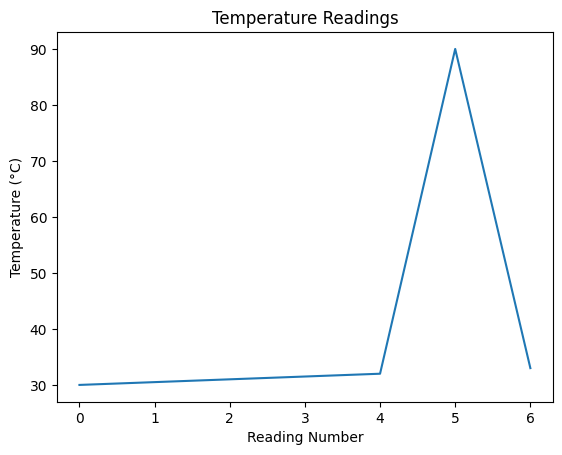

In [ ]:
import matplotlib.pyplot as plt

plt.plot(weather_table["Temperature"])
plt.title("Temperature Readings")
plt.xlabel("Reading Number")
plt.ylabel("Temperature (°C)")
plt.show()

In [ ]:
temperature_mean = weather_table["Temperature"].mean()
temperature_std = weather_table["Temperature"].std()

print("Average temperature:", temperature_mean)
print("Standard deviation:", temperature_std)

Average temperature: 39.714285714285715
Standard deviation: 22.19582757873114


In [ ]:
for temp in weather_table["Temperature"]:
    difference = abs(temp - temperature_mean)

    if difference > temperature_std:
        print(temp, "🚨 Unusual")
    else:
        print(temp, "✅ Normal")

30.0 ✅ Normal
30.5 ✅ Normal
31.0 ✅ Normal
31.5 ✅ Normal
32.0 ✅ Normal
90.0 🚨 Unusual
33.0 ✅ Normal


In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    "Temperature": np.random.normal(30, 2, 500),
    "Humidity": np.random.normal(70, 5, 500),
    "Pressure": np.random.normal(1008, 3, 500)
}

weather_data = pd.DataFrame(data)

print(weather_data.head())

   Temperature   Humidity     Pressure
0    30.993428  74.630888  1012.198066
1    29.723471  79.547083  1010.773901
2    31.295377  63.007162  1008.178891
3    33.046060  72.814846  1006.059190
4    29.531693  66.746787  1010.094670


In [ ]:
print("Number of readings:", len(weather_data))

Number of readings: 500


In [ ]:
print(weather_data.describe())

       Temperature    Humidity     Pressure
count   500.000000  500.000000   500.000000
mean     30.013676   70.159131  1008.325454
std       1.962506    4.889986     3.030739
min      23.517465   56.515567   999.311234
25%      28.599385   67.023541  1006.192711
50%      30.025594   70.142658  1008.359418
75%      31.273567   73.256211  1010.264215
max      37.705463   83.161910  1015.805049


In [ ]:
# Create some faulty sensor readings

weather_data.loc[100, "Temperature"] = 90

weather_data.loc[200:210, "Temperature"] = 25

weather_data.loc[300, "Humidity"] = 150

print(weather_data.iloc[[100, 200, 205, 300]])

     Temperature    Humidity     Pressure
100     90.00000   73.784943  1010.994030
200     25.00000   67.386385  1008.375674
205     25.00000   73.030050  1008.121775
300     28.34201  150.000000  1005.995729


In [ ]:
from sklearn.ensemble import IsolationForest

features = weather_data[["Temperature", "Humidity", "Pressure"]]

model = IsolationForest(
    contamination=0.05,
    random_state=42
)

model.fit(features)

weather_data["Anomaly"] = model.predict(features)

print(weather_data.head())

   Temperature   Humidity     Pressure  Anomaly
0    30.993428  74.630888  1012.198066        1
1    29.723471  79.547083  1010.773901        1
2    31.295377  63.007162  1008.178891        1
3    33.046060  72.814846  1006.059190        1
4    29.531693  66.746787  1010.094670        1


In [ ]:
anomalies = weather_data[weather_data["Anomaly"] == -1]

print(anomalies)

     Temperature    Humidity     Pressure  Anomaly
31     33.704556   61.692400  1002.994248       -1
44     27.042956   57.641777  1007.482118       -1
61     29.628682   80.377004   999.454372       -1
83     28.963460   81.353464  1014.230244       -1
100    90.000000   73.784943  1010.994030       -1
101    29.158709   65.389173   999.311234       -1
146    27.526099   56.515567  1004.711175       -1
154    30.586145   82.866799  1012.926045       -1
179    35.440338   76.357775  1004.689232       -1
207    25.000000   78.773971  1006.011297       -1
208    25.000000   59.590353  1003.792184       -1
209    25.000000   78.482282  1013.248730       -1
220    34.629317   71.539009  1004.437205       -1
233    28.696799   61.487082  1015.739128       -1
252    34.244312   65.120634  1002.018793       -1
262    23.517465   82.800423  1009.616268       -1
300    28.342010  150.000000  1005.995729       -1
346    27.103831   71.445843  1000.338237       -1
355    27.994941   67.146269  1

In [ ]:
print("Number of anomalies detected:", len(anomalies))

Number of anomalies detected: 25


In [ ]:
print("Total readings:", len(weather_data))
print("Anomalies detected:", len(anomalies))
print("Normal readings:", len(weather_data) - len(anomalies))

Total readings: 500
Anomalies detected: 25
Normal readings: 475


In [ ]:
for index, row in weather_data.iterrows():

    if row["Anomaly"] == -1:

        print("🚨 ANOMALY DETECTED")
        print("Reading:", index)
        print("Temperature:", round(row["Temperature"], 2), "°C")
        print("Humidity:", round(row["Humidity"], 2), "%")
        print("Pressure:", round(row["Pressure"], 2), "hPa")
        print("--------------------------")

🚨 ANOMALY DETECTED
Reading: 31
Temperature: 33.7 °C
Humidity: 61.69 %
Pressure: 1002.99 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 44
Temperature: 27.04 °C
Humidity: 57.64 %
Pressure: 1007.48 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 61
Temperature: 29.63 °C
Humidity: 80.38 %
Pressure: 999.45 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 83
Temperature: 28.96 °C
Humidity: 81.35 %
Pressure: 1014.23 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 100
Temperature: 90.0 °C
Humidity: 73.78 %
Pressure: 1010.99 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 101
Temperature: 29.16 °C
Humidity: 65.39 %
Pressure: 999.31 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 146
Temperature: 27.53 °C
Humidity: 56.52 %
Pressure: 1004.71 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 154
Temperature: 30.59 °C
Humidity: 82.87 %
Pressure: 1012.93 hPa
--------------------------
🚨 ANOMALY DETECTED
Reading: 179
Temperat